# Statistics and Trends: Student Mathematics Performance

**Dataset:** `student-mat.csv`  
**Purpose:** Explore the distribution of final mathematics grades, the relationship between first-period and final grades, and differences in final grades across previous-failure groups.

This notebook contains the data checks, descriptive statistics and three visualisations used in the report.

## 1. Import libraries and load the dataset

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset once and reuse df throughout the notebook
DATA_PATH = '/content/student-mat.csv'
df = pd.read_csv(DATA_PATH)

print(f'Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns')
print('Column names:', df.columns.tolist())

Dataset shape: 395 rows × 33 columns
Column names: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


## 2. Explore and check the data

In [ ]:
# Review column names, data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [ ]:
# Check missing values and duplicate rows
print('Missing values by column:')
display(df.isnull().sum())

print('Total duplicate rows:', df.duplicated().sum())

Missing values by column:


,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


Total duplicate rows: 0


In [ ]:
# View descriptive statistics for the grade columns
display(df[['G1', 'G2', 'G3']].describe())

,G1,G2,G3
count,395.000000,395.000000,395.000000
mean,10.908861,10.713924,10.415190
std,3.319195,3.761505,4.581443
min,3.000000,0.000000,0.000000
25%,8.000000,9.000000,8.000000
50%,11.000000,11.000000,11.000000
75%,13.000000,13.000000,14.000000
max,19.000000,19.000000,20.000000


## 3. Figure 1 – Distribution of final mathematics grades (G3)

The histogram shows how the final mathematics grades are distributed. The summary box reports the mean, median, standard deviation and number of students.

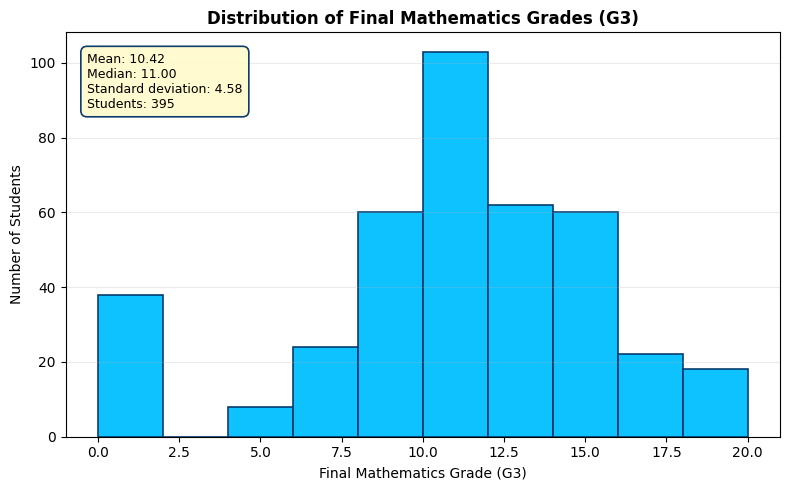

In [ ]:
# Calculate summary statistics for G3
mean_grade = df['G3'].mean()
median_grade = df['G3'].median()
std_grade = df['G3'].std()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(
    df['G3'],
    bins=10,
    color='#00BFFF',
    edgecolor='#003366',
    linewidth=1.2,
    alpha=0.95
)

ax.set_title('Distribution of Final Mathematics Grades (G3)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Final Mathematics Grade (G3)')
ax.set_ylabel('Number of Students')
ax.grid(axis='y', alpha=0.25)

def add_summary_box(ax, text, edge_colour):
    ax.text(
        0.03, 0.95, text,
        transform=ax.transAxes,
        fontsize=9,
        verticalalignment='top',
        bbox=dict(
            boxstyle='round,pad=0.5',
            facecolor='#FFFACD',
            edgecolor=edge_colour,
            linewidth=1.2,
            alpha=0.95
        )
    )

histogram_summary = (
    f'Mean: {mean_grade:.2f}\n'
    f'Median: {median_grade:.2f}\n'
    f'Standard deviation: {std_grade:.2f}\n'
    f'Students: {len(df)}'
)
add_summary_box(ax, histogram_summary, '#003366')

fig.tight_layout()
fig.savefig('histogram_G3.png', dpi=300, bbox_inches='tight')
plt.show()

## 4. Figure 2 – Relationship between first-period and final grades

The scatter plot compares G1 and G3. The Pearson correlation coefficient summarises the strength and direction of their linear relationship.

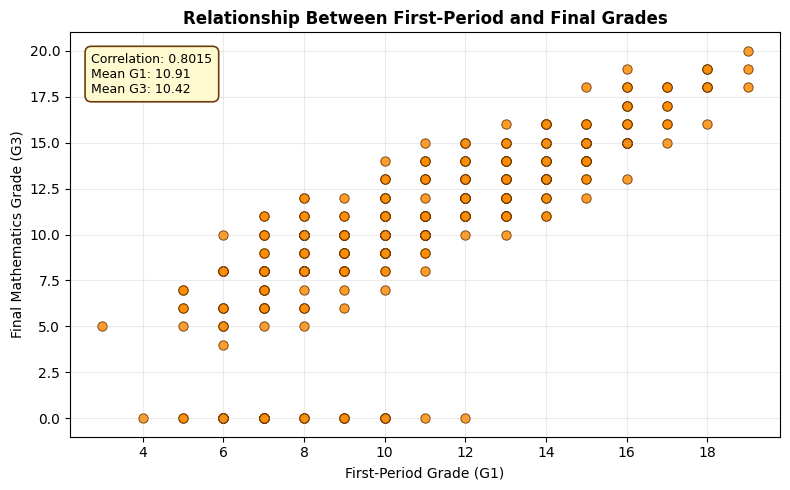

In [ ]:
# Calculate the correlation and average grades
correlation = df['G1'].corr(df['G3'])
mean_g1 = df['G1'].mean()
mean_g3 = df['G3'].mean()


fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    df['G1'], df['G3'],
    color='#FF8C00',
    alpha=0.85,
    edgecolors='#663300',
    linewidths=0.7,
    s=45
)

ax.set_title('Relationship Between First-Period and Final Grades',
             fontsize=12, fontweight='bold')
ax.set_xlabel('First-Period Grade (G1)')
ax.set_ylabel('Final Mathematics Grade (G3)')
ax.grid(alpha=0.25)

scatter_summary = (
    f'Correlation: {correlation:.4f}\n'
    f'Mean G1: {mean_g1:.2f}\n'
    f'Mean G3: {mean_g3:.2f}'
)
add_summary_box(ax, scatter_summary, '#663300')

fig.tight_layout()
fig.savefig('scatter_G1_G3.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Figure 3 – Final grades by previous class failures

The box plot compares the distribution of G3 for each number of previous class failures. The median for each group is also displayed in the summary box.

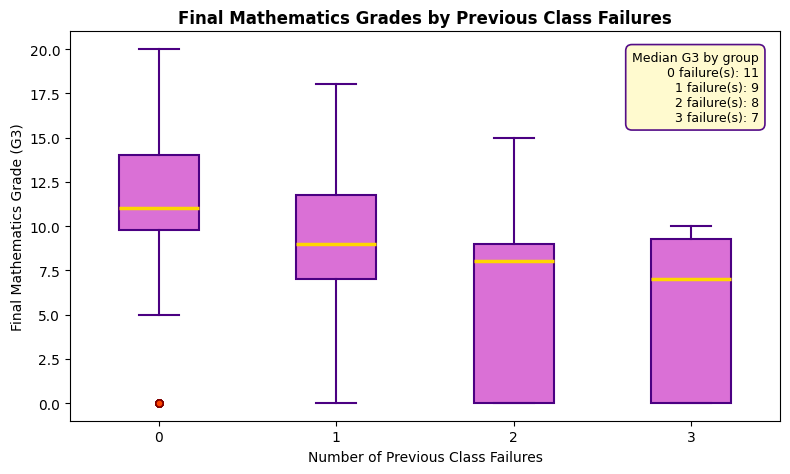

In [ ]:
# Calculate median G3 for each failure group
median_grades = df.groupby('failures')['G3'].median()


ax = df.boxplot(
    column='G3',
    by='failures',
    grid=False,
    figsize=(8, 5),
    patch_artist=True,
    boxprops=dict(facecolor='#DA70D6', color='#4B0082', linewidth=1.5),
    medianprops=dict(color='#FFD700', linewidth=2.5),
    whiskerprops=dict(color='#4B0082', linewidth=1.5),
    capprops=dict(color='#4B0082', linewidth=1.5),
    flierprops=dict(
        marker='o',
        markerfacecolor='#FF4500',
        markeredgecolor='#800000',
        markersize=5
    )
)

plt.suptitle('')
ax.set_title('Final Mathematics Grades by Previous Class Failures',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Number of Previous Class Failures')
ax.set_ylabel('Final Mathematics Grade (G3)')

median_text = 'Median G3 by group\n' + '\n'.join(
    f'{int(group)} failure(s): {value:.0f}'
    for group, value in median_grades.items()
)
ax.text(
    0.97, 0.95, median_text,
    transform=ax.transAxes,
    fontsize=9,
    horizontalalignment='right',
    verticalalignment='top',
    bbox=dict(
        boxstyle='round,pad=0.5',
        facecolor='#FFFACD',
        edgecolor='#4B0082',
        linewidth=1.2,
        alpha=0.95
    )
)

plt.tight_layout()
plt.savefig('boxplot_G3_failures.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Key numerical results

Use these results when checking the values discussed in the report. Explain the patterns in your own words and avoid claiming that previous failures cause lower grades; this analysis shows an association only.

In [ ]:
print(f'Number of students: {len(df)}')
print(f'Mean G3: {mean_grade:.2f}')
print(f'Median G3: {median_grade:.2f}')
print(f'Standard deviation of G3: {std_grade:.2f}')
print(f'Correlation between G1 and G3: {correlation:.4f}')

print('Median G3 by previous-failure group:')
display(median_grades.rename('Median G3').to_frame())

Number of students: 395
Mean G3: 10.42
Median G3: 11.00
Standard deviation of G3: 4.58
Correlation between G1 and G3: 0.8015
Median G3 by previous-failure group:


,Median G3
failures,
0,11.0
1,9.0
2,8.0
3,7.0
